# Simple Linear Regression

## Bengaluru house price prediction

### Step 1:- Import Libraries 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Step 2:- Load Dataset 

In [2]:
data = pd.read_csv(r"E:\AI_ML_Training\AI_ML\raw_materials\Bengaluru_House_Price.csv")
data.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [3]:
print("Dataset colums:")
print(data.columns, "\n")

print("Dataset datatypes:")
print(data.dtypes, "\n")

print("Dataset shape:")
print(data.shape)

Dataset colums:
Index(['area_type', 'availability', 'location', 'size', 'society',
       'total_sqft', 'bath', 'balcony', 'price'],
      dtype='object') 

Dataset datatypes:
area_type        object
availability     object
location         object
size             object
society          object
total_sqft       object
bath            float64
balcony         float64
price           float64
dtype: object 

Dataset shape:
(13320, 9)


### Step 3:- Checking Missing Values

In [4]:
data.isnull().sum()

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

### Step 4:- Check basic statistics

In [5]:
data.describe()

,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


### Step 5:- Select required columns

In [6]:
data_2 = data[['price', 'total_sqft']].copy()
data_2.head()

,price,total_sqft
0,39.07,1056
1,120.00,2600
2,62.00,1440
3,95.00,1521
4,51.00,1200


### Step 6:- Convert Total_sqft into numeric format

In [7]:
pd.set_option('display.max_rows', None)
print(data_2)

          price         total_sqft
0        39.070               1056
1       120.000               2600
2        62.000               1440
3        95.000               1521
4        51.000               1200
5        38.000               1170
6       204.000               2732
7       600.000               3300
8        63.250               1310
9       370.000               1020
10       70.000               1800
11      295.000               2785
12       38.000               1000
13       40.000               1100
14      148.000               2250
15       73.500               1175
16       48.000               1180
17       60.000               1540
18      290.000               2770
19       48.000               1100
20       15.000                600
21      122.000               1755
22      380.000               2800
23      103.000               1767
24       25.250                510
25       56.000               1250
26       23.100                660
27       81.000     

In [8]:
def convert_total_sqft_in_num(value):
    value = str(value).strip()

    if "-" in value:
        parts = value.split("-")

        try:
            low = float(parts[0])
            high = float(parts[1])

            return (low + high)/2

        except:
            return np.nan

    try:
        return float(value)
    except:
        return np.nan

data_2['total_sqft'] = data_2['total_sqft'].apply(convert_total_sqft_in_num)

### step 7:- Check Conversion

In [9]:
print("After converting total sqft in numerical datatype :")
print(data_2.head())

After converting total sqft in numerical datatype :
    price  total_sqft
0   39.07      1056.0
1  120.00      2600.0
2   62.00      1440.0
3   95.00      1521.0
4   51.00      1200.0


In [10]:
data_2.isnull().sum()

price          0
total_sqft    46
dtype: int64

### Step 8:- Remove rows with missing values

In [11]:
data_2 = data_2.dropna()

In [12]:
print("Dataset shape after cleaning :")
print(data_2.shape)

Dataset shape after cleaning :
(13274, 2)


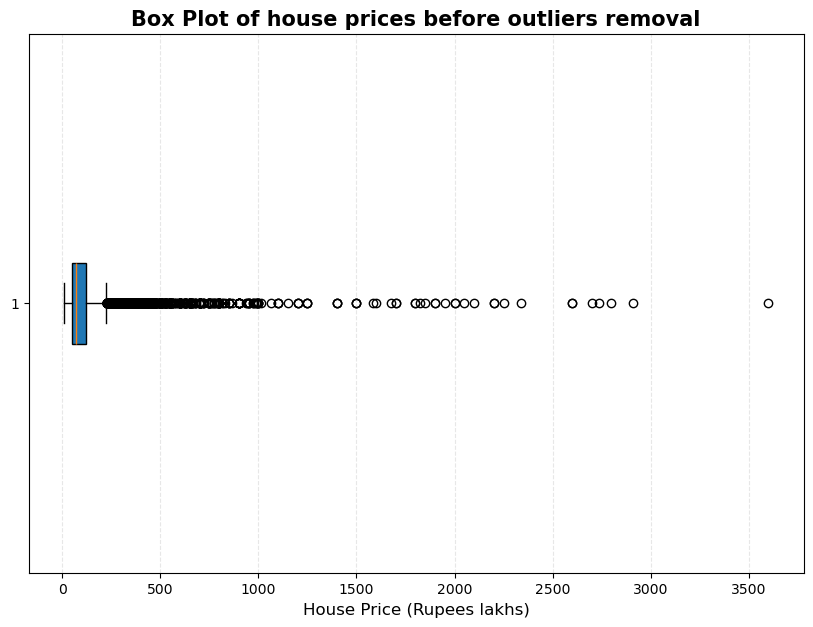

In [13]:
plt.figure(figsize= (10,7))

plt.boxplot(data_2['price'], vert = False, patch_artist = True)
plt.xlabel("House Price (Rupees lakhs)", fontsize = 12)
plt.title("Box Plot of house prices before outliers removal", fontsize = 15, fontweight = "bold")
plt.grid(axis = "x", linestyle = "--", alpha = 0.3)

plt.show()

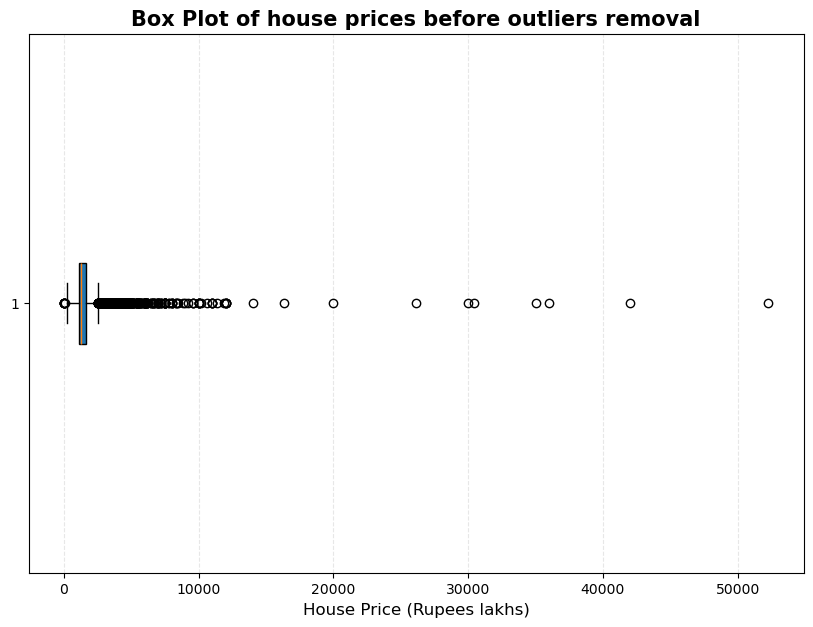

In [14]:
plt.figure(figsize= (10,7))

plt.boxplot(data_2['total_sqft'], vert = False, patch_artist = True)
plt.xlabel("House Price (Rupees lakhs)", fontsize = 12)
plt.title("Box Plot of house prices before outliers removal", fontsize = 15, fontweight = "bold")
plt.grid(axis = "x", linestyle = "--", alpha = 0.3)

plt.show()

In [15]:
def remove_outlier_IQR(data_2, column):
    Q1 = data_2[column].quantile(0.25)

    Q3 = data_2[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5*IQR
    upper_bound = Q3 + 1.5*IQR

    print(f"{column} outlier boundaries :")
    print("Q1 : ", Q1)
    print("Q2 : ", Q3)
    print("IQR : ", IQR)
    print("lower_bound :", lower_bound)
    print("Upper_bound :", upper_bound)

    filtered_data = data_2[(data_2[column] >= lower_bound) & (data_2[column] <= upper_bound)]

    return filtered_data

### Remove total sqft outliers

In [16]:
data_2 = remove_outlier_IQR(data_2, 'total_sqft')

print("After total sqft outlier removal")
data_2.shape

total_sqft outlier boundaries :
Q1 :  1100.0
Q2 :  1680.0
IQR :  580.0
lower_bound : 230.0
Upper_bound : 2550.0
After total sqft outlier removal


(12106, 2)

In [17]:
data_2 = remove_outlier_IQR(data_2, 'price')

print("After price outleir removal")
data_2.shape

price outlier boundaries :
Q1 :  48.0
Q2 :  100.0
IQR :  52.0
lower_bound : -30.0
Upper_bound : 178.0
After price outleir removal


(11227, 2)

### Box Plot after removing the outliers

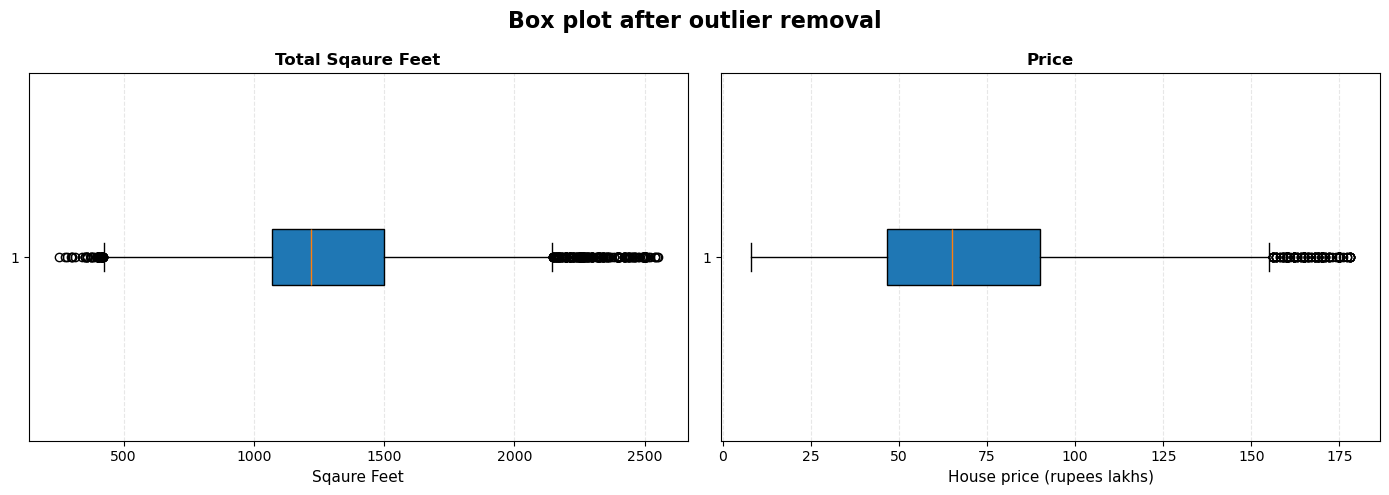

In [18]:
fig, axes = plt.subplots(1,2, figsize = (14, 5))

axes[0].boxplot(data_2['total_sqft'], vert = False, patch_artist = True)
axes[0].set_title("Total Sqaure Feet", fontsize = 12, fontweight = "bold")
axes[0].set_xlabel("Sqaure Feet", fontsize = 11)
axes[0].grid(axis = 'x', linestyle = "--", alpha = 0.3)

axes[1].boxplot(data_2['price'], vert = False, patch_artist = True)
axes[1].set_title("Price", fontsize = 12, fontweight = "bold")
axes[1].set_xlabel("House price (rupees lakhs)", fontsize = 11)
axes[1].grid(axis = 'x', linestyle = "--", alpha = 0.3)

plt.suptitle("Box plot after outlier removal", fontsize = 16, fontweight = "bold")
plt.tight_layout()

In [19]:
x = data_2[['total_sqft']]
y = data_2['price']

In [20]:
x_tn, x_te, y_tn, y_te = train_test_split(x, y, test_size=0.2, random_state=42)
print(f"Shape of x_train : {x_tn.shape}")
print(f"Shape of x_test : {x_te.shape}")
print(f"Shape of y_train : {y_tn.shape}")
print(f"Shape of y_test : {y_te.shape}")

Shape of x_train : (8981, 1)
Shape of x_test : (2246, 1)
Shape of y_train : (8981,)
Shape of y_test : (2246,)


In [21]:
lin_model = LinearRegression()

In [22]:
lin_model.fit(x_tn, y_tn)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [23]:
y_p = lin_model.predict(x_te)
print(f" Mean Absolute Error on Test Data : {mean_absolute_error(y_te, y_p)}")
print(f" Mean Squared Error on Test Data: {mean_squared_error(y_te, y_p)}")
print(f" R2 score on Test Data : {r2_score(y_te, y_p)}")

 Mean Absolute Error on Test Data : 20.147832516194
 Mean Squared Error on Test Data: 753.1955591522996
 R2 score on Test Data : 0.36924767803477454


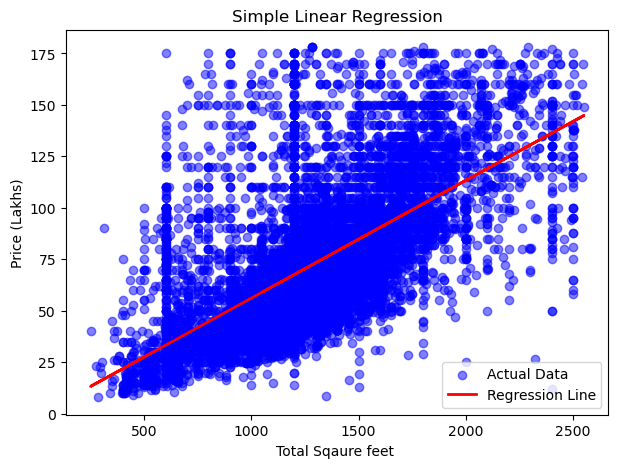

In [27]:
plt.figure(figsize=(7,5))

plt.scatter(x, y, color="blue", label="Actual Data", alpha = 0.5)

plt.plot(x, lin_model.predict(x),
         color="red",
         linewidth=2,
         label="Regression Line")

plt.xlabel("Total Sqaure feet ")
plt.ylabel("Price (Lakhs)")
plt.title("Simple Linear Regression")
plt.legend()

plt.show()

In [25]:
pred = lin_model.predict(x)

In [26]:
print(f" Mean Absolute Error on full Data : {mean_absolute_error(y, pred)}")
print(f" Mean Squared Error on full Data: {mean_squared_error(y, pred)}")
print(f" R2 score on full Data : {r2_score(y, pred)}")

 Mean Absolute Error on full Data : 19.891781943899588
 Mean Squared Error on full Data: 724.0323117237454
 R2 score on full Data : 0.3890866836960155
